In [1]:
# 更新履歴
## 2026/02/24 fitを個別にできるようにした
## 2026/02/08 新規作成
## 2025/12/23 機能追加
## 2025/12/22 作成

# 基本モジュール
import sys, os
from IPython.display import display, HTML, clear_output, update_display, Image
from tqdm import tqdm
import pyperclip
import pickle as pkl
import json

# データ分析用
import numpy as np
import scipy as sp
import pandas as pd
import h5py

# グラフ描画用
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.express as px
import plotly.graph_objects as go
import PIL.Image as im

# XRDk切り開き用（不要かも）
import pyFAI

# 自作モジュール
sys.path.append(r"C:\Users\okaza\pythonenv")
from modules.Mytools.Tools import h5_tree, dict_tree, his2array, print_fileinfo, simple_progress_bar
from modules.peakfit import peakfit
import modules.Mytools.Settings

# 初期パラメーター
cachedir = os.path.join(os.getcwd(), ".cache")
os.makedirs(cachedir, exist_ok=True)
print("cache: " + os.path.abspath(cachedir))

cache: c:\Users\okaza\Documents\Documents\fpd\PeakFit\.cache


In [2]:
# ベースラインを計算する関数
def bead(signal, lam=1e6, d=2, ratio=0.01, max_iter=50):
    """
    BEAD: Baseline Estimation And Denoising
    
    Parameters
    ----------
    signal : array
        入力信号（XRD強度）
    lam : float
        平滑化パラメータ（大きいほど滑らか）
    d : int
        微分次数
    ratio : float
        非対称性パラメータ
    max_iter : int
        反復回数
        
    Returns
    -------
    baseline : array
        推定されたバックグラウンド
    """

    signal = np.asarray(signal)
    N = len(signal)

    # --- 差分行列生成 ---
    D = sp.sparse.eye(N, format='csc')
    for _ in range(d):
        D = D[1:, :] - D[:-1, :]

    H = lam * (D.T @ D)

    w = np.ones(N)

    for _ in range(max_iter):
        W = sp.sparse.diags(w, 0, shape=(N, N))
        Z = W + H

        baseline = sp.sparse.linalg.spsolve(Z, w * signal)

        diff = signal - baseline
        w = ratio * (diff > 0) + (1 - ratio) * (diff < 0)

    return baseline

## 目的

1次元XRDデータ(hdfファイル)をフィッティングする

## ファイル読み込み

In [5]:
# 切り開きを行ったhdfファイルあるいはcsvファイル
hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\32\UODE54_0032_integrate1d.hdf"
# hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\Retracted_XRD\UODE56_0018_0-16.csv"
# hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\Retracted_XRD\UODE56_0018_59-63.csv"
# hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\Retracted_XRD\UODE56_0018_71-80.csv"
# hdf_1d = r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\Retracted_XRD\UODE56_0018_95-101.csv"

In [97]:
# ファイルを読み込んで、plotlyで出力する
def get_data(raw: str,
             ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:

    # データ読み込み
    ity = []
    bg = []
    if os.path.splitext(raw)[1] == ".hdf":
        with h5py.File(raw, mode = "r") as f:
            tth = np.array(f["rad"][()]) # type: ignore
            for i in range(len(list(f["integrated"].keys()))): # type: ignore
                intensity = f["integrated/frame = {}".format(i)][()] # type: ignore
                baseline = bead(
                    signal = intensity,
                    lam = 1e8,
                    d = 2,
                    ratio = 0.01,
                )
                ity.append(intensity)
                bg.append(baseline)
    elif os.path.splitext(raw)[1] == ".csv":
        df = pd.read_csv(
            r"D:\DATA\SPring-8-2026-July\Okazaki\Analysis\UODE54\18\UODE56_0018_96-101.csv",
            header = None,
            index_col = None
        )
        tth = np.array(df[0])
        intensity = np.array(df[1])
        baseline = bead(
            signal = intensity,
            lam = 1e8,
            d = 2,
            ratio = 0.01,
        )
        ity.append(intensity)
        bg.append(baseline)
            
    ity = np.vstack(ity)
    bg = np.vstack(bg)

    # figure作成
    if True:

        # インスタント化
        fig = go.Figure()

        # 一枚目作成
        raw_anim = go.Scatter(
            x = tth,
            y = ity[0] - bg[0],
            mode = "lines",
            line = dict(
                color = "#000000",
                width = 1,
            )
        )
        fig.add_trace(raw_anim)

        # アニメーションフレームを作成
        frame_list = [
            go.Frame(
                data = [
                    go.Scatter(
                        y = ity[k] - bg[k]
                    )
                ],
                name = str(k),
            ) for k in range(ity.shape[0])
        ]
        fig.frames = frame_list

        # フレーム変更用のボタンとスライダー
        updatemenus_frame = dict(
            type='buttons',
            direction = 'left', # 横並びの場合 'left', 縦並びの場合 'down'
            showactive=False,
            active = -1,
            y=0,
            x=0,
            xanchor='left',
            yanchor='top',
            pad=dict(t=65, r=0),
            buttons=[
                dict(
                    label='▶︎',
                    method='animate',
                    args=[
                        None,
                        dict(
                            frame=dict(
                                duration=200,
                                redraw=True
                            ),
                            fromcurrent=True,
                            mode='immediate',
                            transition=dict(duration=0)
                        )
                    ]
                ),
                dict(
                    label='⏸',
                    method='animate',
                    args=[
                        [None],
                        dict(
                            frame=dict(
                                duration=0,
                                redraw=False
                            ),
                            mode='immediate',
                            transition=dict(duration=0)
                        )
                    ]
                )
            ],
            visible = True
        )
        slider = dict(
            steps=[dict(
                method='animate',
                args=[
                    [str(k)],
                    dict(
                        mode='immediate',
                        frame=dict(
                            duration=0,
                            redraw=True
                            ),
                        transition=dict(
                            duration=0
                        )
                    )
                ],
                label=str(k),
            ) for k in range(ity.shape[0])],
            ticklen = 0,
            minorticklen = 0,
            active=0,
            y=0,
            x=0, # スライダーの開始位置
            len=1, # スライダーの長さ
            xanchor='left',
            yanchor='top',
            pad=dict(
                b=10,
                t=50,
                l=100
            ),
            currentvalue=dict(
                prefix='Frame = ',
                visible=True,
                xanchor='left'
            ),
            visible = True,
        )

        fig.update_layout(
            title = dict(
                text = os.path.splitext(os.path.basename(raw))[0],
                font = dict(
                    size = 26,
                    color = "#777777"
                ),
                x = 0.05,
                y = 0.95,
                xanchor = "left",
                yanchor = "top",
            ),
            xaxis = {
                'title': "2theta [deg.]",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            yaxis = {
                'title': "Intensity",
                "linecolor": "#000000",
                "linewidth": 1,
                'ticks': "inside",
                "tickcolor": "#000000",
                "tickwidth": 1,
                "ticklen": 5,
                'mirror': True,
            },
            plot_bgcolor = '#ffffff',
            updatemenus = [
                updatemenus_frame,
            ],
            sliders = [slider],
            showlegend = False,
            legend = dict(
                bordercolor = "#000000",
                orientation = "h",
                yanchor = "bottom",
                y = 1,
                bgcolor = "rgba(255,255,255,0)",
                xanchor = "center",
                x = 0.5
            ),
            width = 800,
            height = 600,
        )

        fig.show()

    return (tth, ity, bg)
tth, ity, bg = get_data(hdf_1d)
del get_data

## フィッティング

In [95]:
# パラメーターを格納したjsonファイルを指定します。
params = r"C:\Users\okaza\Documents\Documents\fpd\PeakFit\fit_param.json"
params = r"C:\Users\okaza\Documents\Documents\fpd\PeakFit\fit_param - コピー (2) - コピー - コピー.json"

<class 'dict'>  (size = 0.00 MB)
├── profile
│   ├── background
│   │   ├── #0 <class 'float'>
│   │   └── #1 <class 'float'>
│   └── peaks
│       ├── #0
│       │   ├── center <class 'float'>
│       │   ├── height <class 'float'>
│       │   ├── fwhm <class 'float'>
│       │   └── factor <class 'float'>
│       ├── #1
│       │   ├── center <class 'float'>
│       │   ├── height <class 'float'>
│       │   ├── fwhm <class 'float'>
│       │   └── factor <class 'float'>
│       ├── #2
│       │   ├── center <class 'float'>
│       │   ├── height <class 'float'>
│       │   ├── fwhm <class 'float'>
│       │   └── factor <class 'float'>
│       ├── #3
│       │   ├── center <class 'float'>
│       │   ├── height <class 'float'>
│       │   ├── fwhm <class 'float'>
│       │   └── factor <class 'float'>
│       └── #4
│           ├── center <class 'float'>
│           ├── height <class 'float'>
│           ├── fwhm <class 'float'>
│           └── factor <class 'float'>
├── fit_len
│  

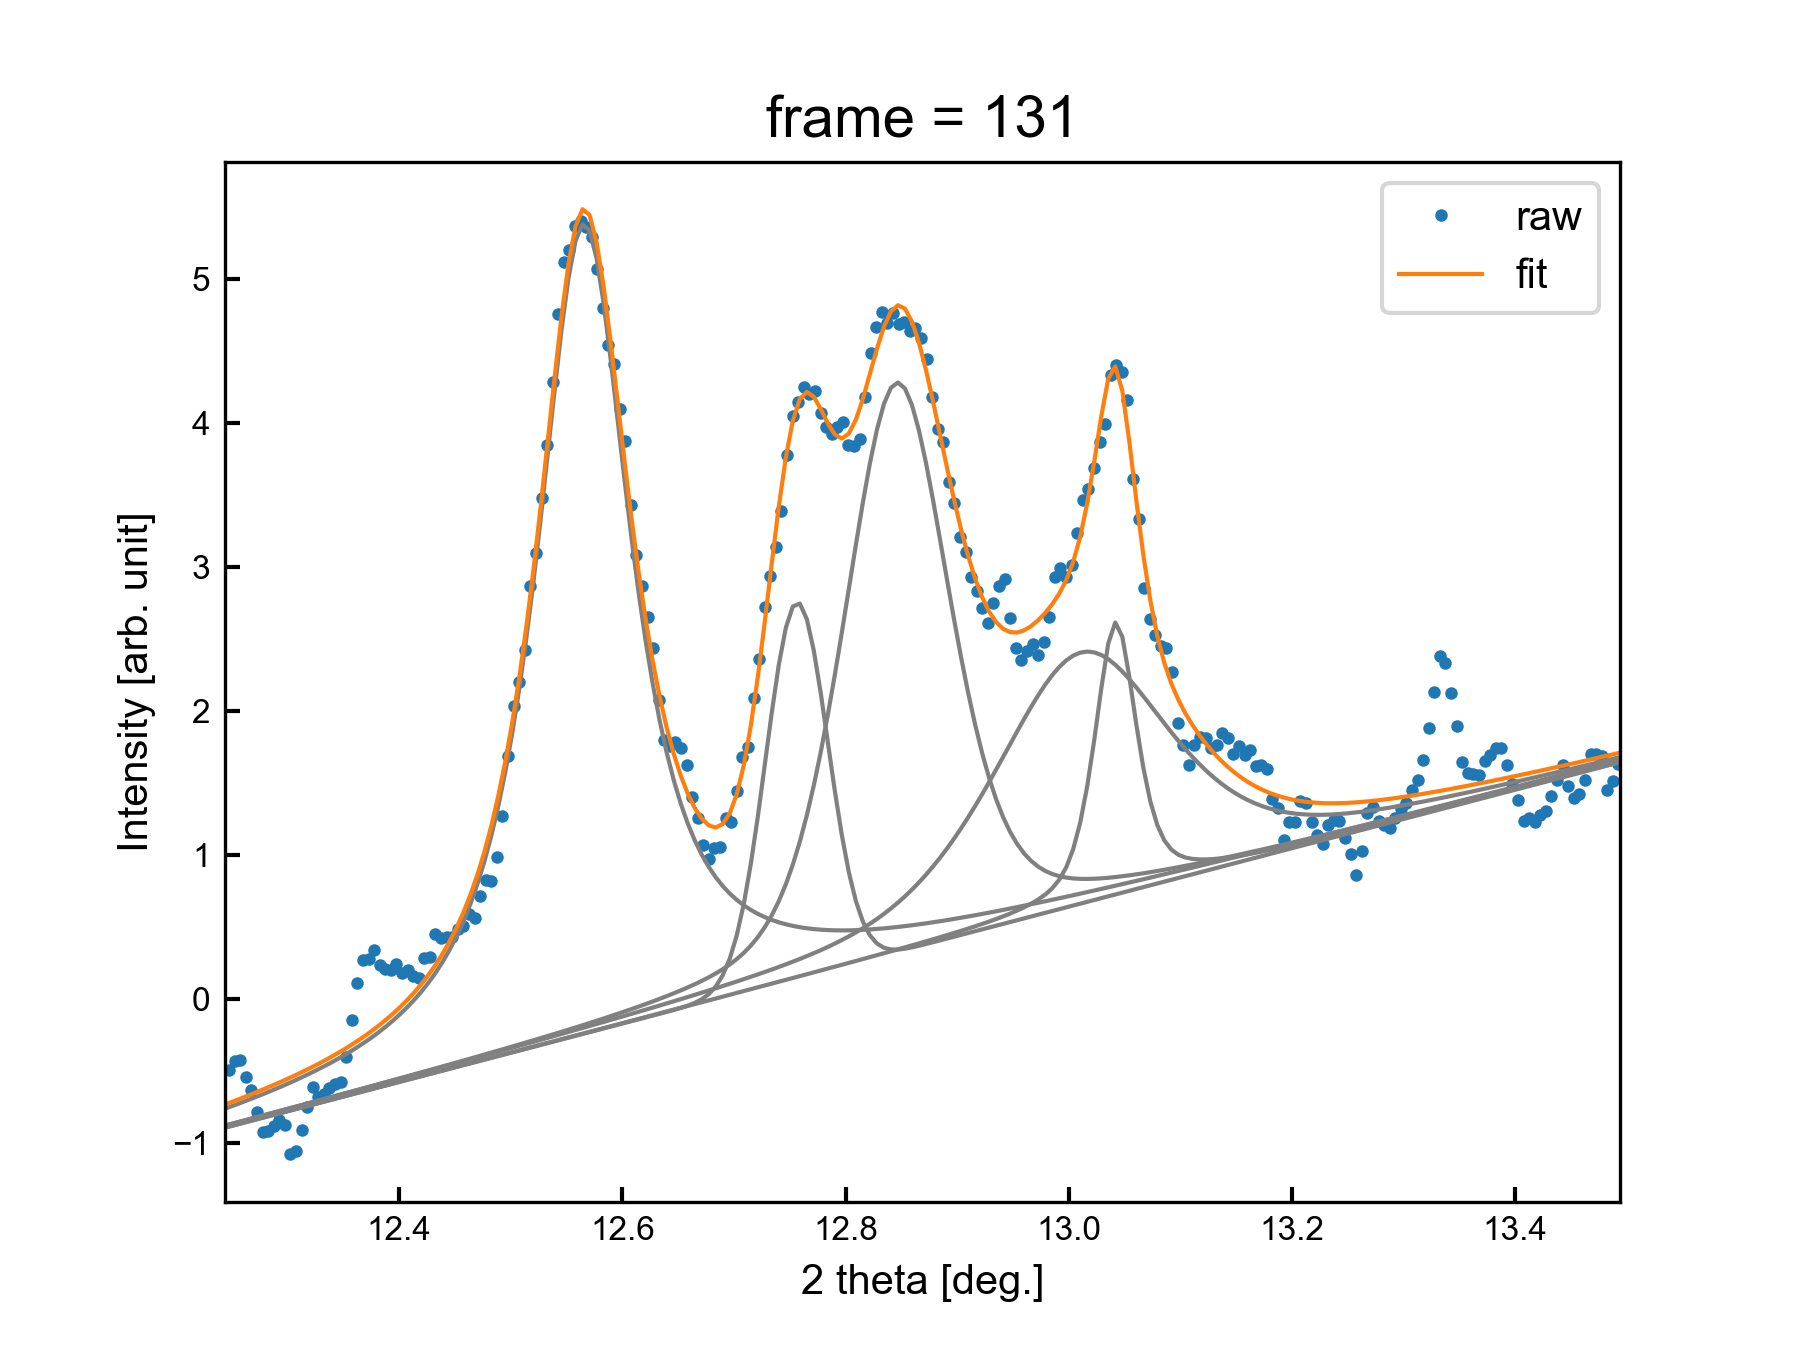

In [143]:
def fit_step(
        tth: np.ndarray,
        ity: np.ndarray,
        param_json: str,
        hdf: str,
    ):

    # パラメータファイルを読み込み
    with open(param_json, mode = "r") as file:
        param = json.load(file)

    # 引数の確認
    print("="*70)
    dict_tree(param)
    print("\n" + "="*70)

    # フィッティング関数は2種類のみ
    if not (param["func"] in ["psdVoigt", "asympsdVoigt"]):
        raise KeyError("func is either 'psdVoigt' or 'asympsdVoigt'")

    # フィッティング用変数
    fit_count = 0
    res_dict = {
        "fitres": {},
        "func": param["func"],
        "hdf": hdf
    }

    # インスタント化
    pf = peakfit()
    
    # 結果の読み込み
    jsonfilename = os.path.join(cachedir, "fitres.json")
    if os.path.exists(jsonfilename):
        with open(jsonfilename, mode = "r") as file:
            res_dict = json.load(file)
        if res_dict["func"] != param["func"]:
            raise KeyError("The fitting function has been changed!")
    
    # フィッティングする関数を定義
    def fit_func(tth: np.ndarray,
                 param_dict: dict,
                 function: str,
                 ) -> np.ndarray:
        
        # 値の格納先
        ity = np.zeros(tth.shape)

        # ピーク関数
        pf = peakfit()
        func = pf.psdVoigt if (function == "psdVoigt") else pf.asympsdVoigt

        # background
        dim_bg = len(param_dict["background"])
        for i in range(dim_bg):
            ity += np.power(tth-tth[0], i) * param_dict["background"]["#{}".format(i)]

        # ピーク
        n_peak = len(param_dict["peaks"])
        for i in range(n_peak):
            ity += func(tth, param_dict["peaks"]["#{}".format(i)])

        return ity

    # フレーム数を計算
    n_frame = ity.shape[0]
    
    while True:

        # データ取得
        d = ity[param["frame"]]
        fit_len = param["fit_len"]
        dim_bg = len(param["profile"]["background"])
        n_peak = len(param["profile"]["peaks"])
        center = np.average([float(param["profile"]["peaks"]["#{}".format(k)]["center"]) for k in range(n_peak)])
        fit_range = tuple(np.array([fit_len[side] for side in ["left", "right"]])*np.array([-1,1]) + center)
        fit_mask = (tth > fit_range[0]) * (tth < fit_range[1])

        if not param["fit"]: # fitしない場合
            break
        
        else: # fitする場合

            # インスタント化
            param_keys, param_values = pf.dict_to_lists(param["profile"])

            # 値域を定義
            bounds_up_bg = [np.inf]*dim_bg
            bounds_down_bg = [-np.inf]*dim_bg
            if param["func"] == "psdVoigt":
                bounds_up_peak = [fit_range[-1], np.inf, np.inf, 1] * n_peak
                bounds_down_peak = [fit_range[0], 0, 0, 0] * n_peak
            else:
                bounds_up_peak = [fit_range[-1], np.inf, np.inf, 1, np.inf, 1] * n_peak
                bounds_down_peak = [fit_range[0], 0, 0, 0, 0, 0] * n_peak
            bounds = (
                tuple(bounds_down_bg + bounds_down_peak),
                tuple(bounds_up_bg + bounds_up_peak)
            )

            # フィッティングに用いる関数を定義
            def f(x, *args):
                p = pf.lists_to_dict(param_keys, list(args))
                return fit_func(x, p, param["func"])
            
            # フィッティングを行う
            methods = ["trf", "dogbox"]
            for method in methods:
                try:
                    popt, pcov = sp.optimize.curve_fit(
                        f,
                        tth[fit_mask],
                        d[fit_mask],
                        p0 = param_values,
                        maxfev = 4000,
                        bounds = bounds,
                        method = method,
                    )
                except RuntimeError as errormessage: # フィッティングがうまく行かなかった場合
                    if method == method[-1]:
                        print("Raise fitting error!")
                        flag_err = True
                        break
                    else:
                        pass
                else: # フィッティングがうまく行った場合
                    param["profile"] = pf.lists_to_dict(keys = param_keys, values = popt)
                    flag_err = False
                    break
            
            # フィッティングがうまく行かなかった場合
            if flag_err:
                break

            # 決定係数の計算
            rss = np.sum(np.square(d[fit_mask] - fit_func(tth[fit_mask], param["profile"], param["func"])))
            tss = np.sum(np.square(d[fit_mask] - np.mean(d[fit_mask])))
            r2 = 1 - rss/tss
            
            if not fit_count: # 初回の場合
                # 変数を引き継ぐ
                fit_count += 1
                current_r2 = r2        
                continue
            else: # 2回目以降の場合
                # 収束判定 (r2に変化がなくなったら終了)
                delta_r2 = (r2 - current_r2)/r2
                
                # 収束した場合
                if (delta_r2 < param["threshold"]) or (fit_count > param["maxfit"]):
                    res_dict["fitres"]["frame = {}".format(param["frame"])] = dict(
                        res = {
                            "params": pf.lists_to_dict(keys = param_keys, values = popt),
                            "error": pf.lists_to_dict(keys = param_keys, values = list(np.sqrt(np.diag(pcov)))),
                            "pcov": pcov.tolist(),
                        },
                        range = fit_range,
                    )
                    fit_count = 0
                    
                    # 続けてフィッティングを行う場合
                    if param["auto"] and (param["frame"] < n_frame-1):
                        param["frame"] += 1
                        simple_progress_bar(current = param["frame"]+1, total = n_frame)
                        continue

                    # 終了する場合
                    else:
                        break
                
                # 収束しなかった場合
                else:
                    fit_count += 1
                    current_r2 = r2
                    continue

    if param["fit"]: # fitした場合
        # fit_param.jsonの更新
        with open(param_json, mode = "w") as file:
            json.dump(param, file, indent = 4)

        # fitres.jsonの保存
        jsonfilename = os.path.join(cachedir, "fitres.json")
        with open(jsonfilename, mode = "w") as file:
            json.dump(res_dict, file, indent = 4)
        print("Save: " + os.path.abspath(jsonfilename))

    # 画像の出力
    def display_fitres(fit_range: tuple,
                       tth: np.ndarray,
                       d: np.ndarray,
                       param_dict: dict,
                       function: str,
                       title: str,
                       ) -> str:
        
        # 演算
        if True:
            # opt
            xs = np.linspace(*fit_range, 200) # type: ignore
            
            # background
            bg = np.zeros(xs.shape)
            dim_bg = len(param_dict["background"])
            for i in range(dim_bg):
                bg += np.power(xs-fit_range[0], i) * param_dict["background"]["#{}".format(i)]
            
            # each peak
            peaks = []
            pf = peakfit()
            func = pf.psdVoigt if (function == "psdVoigt") else pf.asympsdVoigt
            n_peak = len(param_dict["peaks"])
            for i in range(n_peak):
                peaks.append(func(xs, param_dict["peaks"]["#{}".format(i)]) + bg)
            
            # whole profile
            ys = fit_func(xs, param_dict, function)

        # figure作成
        fig, ax = plt.subplots()
        fig.set_size_inches(6,4.5)
        ax.plot(
            tth,
            d,
            lw = 0,
            marker = "o",
            ms = 3,
            c = "tab:blue",
            mew = 0,
            label = "raw",
        )
        for i in range(n_peak):
            ax.plot(
                xs,
                peaks[i],
                c = "0.5",
                lw = 1,
            )
        ax.plot(
            xs,
            ys,
            c = "tab:orange",
            lw = 1,
            label = "fit",
        )
        ax.set_title(title, fontsize = 14)
        ax.legend(fontsize = 10)
        ax.set_xlim(fit_range)
        ax.set_xlabel("2 theta [deg.]", fontsize = 10)
        ax.set_ylabel("Intensity [arb. unit]", fontsize = 10)
        pngfile = os.path.join(os.path.dirname(cachedir), "display_fitres.png")
        plt.savefig(pngfile, dpi = 300)
        plt.close()
        return pngfile
    pngfilename = display_fitres(
        fit_range = fit_range,
        tth = tth[fit_mask],
        d = d[fit_mask],
        param_dict = param["profile"],
        function = param["func"],
        title = "frame = {}".format(param["frame"]),
    )
    print("Save: " + pngfilename)
    display(Image(filename = pngfilename, width = 600))

    return
fit_step(tth = tth,
         ity = ity - bg,
         param_json = params,
         hdf = hdf_1d)
del fit_step